<a href="https://colab.research.google.com/github/amsalu2212/DS_Ass5/blob/main/Ass5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Name: Amsalu Tessema Adgeh**
#**ID Number:2026A8000929002**
# Data Science Assignment 5: Time-Series Rolling Evaluation Lab
**Dataset:** UCI *Individual Household Electric Power Consumption*

**Source** https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

**My assignment main Task:** forecast hourly mean `Global_active_power` (kW) for the next 168 hours (7 days) from each forecast origin, under strict temporal information boundaries, evaluated at 10 expanding rolling origins (plus a sliding-window check).

In [29]:
#First we imports necessary python libraries, seeds, configuration, environment capture etc...
import os, sys, json, hashlib, random, platform, subprocess, zipfile, urllib.request, warnings, time, textwrap, math
from datetime import date, timedelta
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import sklearn, scipy, matplotlib

SEED = 20260
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

ROOT = Path(".").resolve()
DATA_DIR, RES_DIR, FIG_DIR, REP_DIR = ROOT/"data", ROOT/"results", ROOT/"figures", ROOT/"reports"
for d in (DATA_DIR, RES_DIR, FIG_DIR, REP_DIR): d.mkdir(exist_ok=True)

DATA_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
EXPECTED_ZIP_SHA256 = None   # after the first successful run, paste the hash printed below here and commit it (data-version pin)

HORIZON = 168                # forecast horizon in hours (7 days)
SLIDING_DAYS = 365           # training length for the sliding-window check
MIN_VALID_MINUTES = 30       # an hour is valid only if >= 30 of its 60 minutes are observed
# forecast START timestamps (00:00). Last observed hour of each origin = start - 1h.
# 10 expanding origins, all >= 2 years after the data start. 4 are pre-registered CRITICAL origins (flagged below).
ORIGIN_STARTS = ["2009-03-02","2009-05-04","2009-07-06","2009-08-10","2009-10-05",
                 "2009-12-21","2010-02-01","2010-04-01","2010-08-09","2010-11-15"]
CRITICAL_ORIGINS = {"2009-08-10": "Summer holiday window (15 Aug holiday inside)",
                    "2009-12-21": "Christmas / New Year run-up (24-25 Dec inside)",
                    "2010-04-01": "Easter window (Easter Monday 2010-04-05 inside)",
                    "2010-08-09": "Summer holiday window (15 Aug holiday inside)"}
MODELS = ["persistence","snaive24","snaive168","ridge","hgb","hgb_calendar_only"]
ML_PRIMARY = "hgb"           # fixed a priori as the 'production' candidate
FALLBACK_RATIO = 1.10        # a-priori heuristic, not tuned
PSI_ALARM = 0.25
ALARM_DAILY_RATIO = 1.5
REPO_URL = "<FILL_AFTER_PUSH>"   # e.g. https://github.com/<user>/<repo>
REPO_TAG = "v1.0"

ENV = dict(python=sys.version.split()[0], platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__,
           scikit_learn=sklearn.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__, seed=SEED)
print(json.dumps(ENV, indent=2))
try:
    fr = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, timeout=120)
    (RES_DIR/"environment_freeze.txt").write_text(fr.stdout)
except Exception as e:
    print("pip freeze failed (retained as evidence):", repr(e))

{
  "python": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit_learn": "1.6.1",
  "scipy": "1.16.3",
  "matplotlib": "3.10.0",
  "seed": 20260
}


In [30]:
# Then second, load the dataset (Data acquisition + data-version manifest)
txt_path, zip_path = DATA_DIR/"household_power_consumption.txt", DATA_DIR/"household_power_consumption.zip"
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()
#The following downloads the dataset once (or uses `data/household_power_consumption.txt` if present).
if not txt_path.exists():
    if not zip_path.exists():
        print("Downloading", DATA_URL)
        urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        assert "household_power_consumption.txt" in z.namelist(), z.namelist()
        z.extract("household_power_consumption.txt", DATA_DIR)

manifest = dict(source_url=DATA_URL, dataset_page="https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption",
                txt_sha256=sha256(txt_path), zip_sha256=sha256(zip_path) if zip_path.exists() else None)
if EXPECTED_ZIP_SHA256 and manifest["zip_sha256"]:
    assert manifest["zip_sha256"] == EXPECTED_ZIP_SHA256, "Dataset zip differs from pinned version!"
(RES_DIR/"data_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))

{
  "source_url": "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip",
  "dataset_page": "https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption",
  "txt_sha256": "4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7",
  "zip_sha256": "9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263be3b3b3d10dfbda3ff"
}


In [31]:
#Then after thirdly, Minute data -> regular hourly frame + data-quality report ----
mraw = pd.read_csv(txt_path, sep=";", na_values=["?", ""], low_memory=False)
n_minute_rows = len(mraw)
mraw["ts"] = pd.to_datetime(mraw["Date"] + " " + mraw["Time"], format="%d/%m/%Y %H:%M:%S")
assert not mraw["ts"].duplicated().any(), "duplicate timestamps"
num_cols = ["Global_active_power","Global_reactive_power","Voltage","Global_intensity","Sub_metering_1","Sub_metering_2","Sub_metering_3"]
for c in num_cols: mraw[c] = pd.to_numeric(mraw[c], errors="coerce")
mraw = mraw.set_index("ts").sort_index()
na_frac_minute = mraw[num_cols].isna().mean().round(5).to_dict()

g = mraw["Global_active_power"].resample("h")
hourly_mean, hourly_cnt = g.mean(), g.count()
full_idx = pd.date_range(hourly_mean.index.min(), hourly_mean.index.max(), freq="h")
df = pd.DataFrame(index=full_idx)
df["y"] = hourly_mean.reindex(full_idx).where(hourly_cnt.reindex(full_idx) >= MIN_VALID_MINUTES)   # label: NaN if too few minutes
for c in ["Global_reactive_power","Voltage","Global_intensity","Sub_metering_1","Sub_metering_2","Sub_metering_3"]:
    df[c] = mraw[c].resample("h").mean().reindex(full_idx)      # ex-post drift diagnostics ONLY, never model inputs
del mraw

# causal forward-filled copy used ONLY as the source series for the naive baselines (value known at stamp <= s-1h)
df["y_ff"] = df["y"].ffill()
df = df[df["y_ff"].notna()]         # drop leading hours before the first observation (none expected)

# French public holidays from rules (deterministic, known in advance)
def easter(y):
    a=y%19; b=y//100; c=y%100; d=b//4; e=b%4; f=(b+8)//25; g_=(b-f+1)//3; h=(19*a+b-d-g_+15)%30; i=c//4; k=c%4
    l=(32+2*e+2*i-h-k)%7; m=(a+11*h+22*l)//451; month=(h+l-7*m+114)//31; day=((h+l-7*m+114)%31)+1
    return date(y, month, day)
def fr_holidays(years):
    S = set()
    for y in years:
        S |= {date(y,1,1), date(y,5,1), date(y,5,8), date(y,7,14), date(y,8,15), date(y,11,1), date(y,11,11), date(y,12,25)}
        e = easter(y); S |= {e + timedelta(1), e + timedelta(39), e + timedelta(50)}
    return S
assert easter(2010) == date(2010, 4, 4) and easter(2009) == date(2009, 4, 12)
HOL = fr_holidays(range(2006, 2012))
df["is_fr_holiday"] = pd.Index(df.index.date).isin(list(HOL)).astype(float)

miss = df["y"].isna()
run_lengths = (miss != miss.shift()).cumsum()[miss].value_counts()
dq = dict(minute_rows_in_file=int(n_minute_rows), minute_na_fraction=na_frac_minute, hourly_grid_rows=int(len(df)),
          hourly_missing_label=int(miss.sum()), hourly_missing_share=float(miss.mean()),
          longest_missing_run_hours=int(run_lengths.max()) if len(run_lengths) else 0,
          y_min=float(df.y.min()), y_max=float(df.y.max()), y_mean=float(df.y.mean()),
          first_stamp=str(df.index.min()), last_stamp=str(df.index.max()))
(RES_DIR/"data_quality.json").write_text(json.dumps(dq, indent=2)); print(json.dumps(dq, indent=2))
assert df.index.is_monotonic_increasing and df.index.is_unique
assert pd.Timestamp(ORIGIN_STARTS[0]) - pd.Timedelta(days=364) >= df.index.min(), "first origin too early for the last-year reference"
assert pd.Timestamp(ORIGIN_STARTS[-1]) + pd.Timedelta(hours=HORIZON) <= df.index.max() + pd.Timedelta(hours=1), "last window exceeds data"
cov = pd.DataFrame([dict(origin=o, valid_label_share=float(df.y.reindex(pd.date_range(o, periods=HORIZON, freq="h")).notna().mean())) for o in ORIGIN_STARTS])
cov.to_csv(RES_DIR/"window_label_coverage.csv", index=False); print(cov.to_string())

{
  "minute_rows_in_file": 2075259,
  "minute_na_fraction": {
    "Global_active_power": 0.01252,
    "Global_reactive_power": 0.01252,
    "Voltage": 0.01252,
    "Global_intensity": 0.01252,
    "Sub_metering_1": 0.01252,
    "Sub_metering_2": 0.01252,
    "Sub_metering_3": 0.01252
  },
  "hourly_grid_rows": 34589,
  "hourly_missing_label": 432,
  "hourly_missing_share": 0.012489519789528463,
  "longest_missing_run_hours": 120,
  "y_min": 0.12400000000000001,
  "y_max": 6.560533333333334,
  "y_mean": 1.0916370018177342,
  "first_stamp": "2006-12-16 17:00:00",
  "last_stamp": "2010-11-26 21:00:00"
}
       origin  valid_label_share
0  2009-03-02           1.000000
1  2009-05-04           1.000000
2  2009-07-06           1.000000
3  2009-08-10           0.910714
4  2009-10-05           1.000000
5  2009-12-21           1.000000
6  2010-02-01           1.000000
7  2010-04-01           1.000000
8  2010-08-09           1.000000
9  2010-11-15           1.000000


## Feature / label availability map (true availability time)

***Forecast convention***: a forecast *origin* has start time `s` (first hour to predict); only observations with stamp `< s` exist. The label for stamp `t` summarises minutes in `[t, t+1h)`, so it is known only at `t+1h`. Each feature gets an explicit rule.

***Missing data polic***y: missing label hours  are **never filled in the label**; they are excluded from training and from metrics, and window label coverage is reported. Missing lag features are imputed with the *training-window median*, with the imputer refit inside every window.

In [32]:
AVAIL = [('y (LABEL) = hourly mean Global_active_power (kW) at stamp t', 'household_power_consumption.txt, 1-minute rows in [t, t+1h) averaged', 'Known only after the hour ends (t+1h). Treated as available to a forecast starting at s only if stamp t < s. Hour is NaN (missing) if fewer than 30 valid minutes', 'Label; also source of lag features', 'Training labels restricted to observed stamps < s (asserted). Missing hours are NOT filled in the label; excluded from training and from metric computation'), ('hr_sin, hr_cos', 'hour of day of target stamp', 'Deterministic from timestamp', 'Yes', 'Safe'), ('dow_0..dow_6', 'day of week of target stamp', 'Deterministic from timestamp', 'Yes', 'Safe'), ('mon_sin, mon_cos', 'month of target stamp', 'Deterministic from timestamp', 'Yes', 'Safe'), ('is_fr_holiday', 'French public holiday flag computed from rules (fixed dates + Easter Monday, Ascension, Whit Monday)', 'Fixed by law/astronomical rule; known years ahead', 'Yes', 'Safe. Household is in Sceaux (Paris region), France'), ('lag168', 'y at t-168h', 'Known at t-168h+1h <= s whenever forecast horizon <= 168h', 'Yes', 'Horizon fixed at 168h so the lag is always observed (verified by truncation-invariance test). NaN if that hour was a sensor gap'), ('lag336', 'y at t-336h', 'Same as lag168 (older)', 'Yes', 'Safe; NaN possible'), ('mean24_at_lag168', 'mean of y over the 24h ending at t-168h (needs >= 12 valid hours)', 'Known at t-168h+1h <= s', 'Yes', 'Safe; NaN possible'), ('NaN imputation of lag features', 'median of the training window', 'Computed from training rows only', 'Inside pipeline', 'SimpleImputer is refit inside every window (preprocessing refit requirement)'), ('Global_reactive_power, Voltage, Global_intensity at t', 'same-hour mean of observed electrical measurements', 'Observed only during/after hour t; NOT known at origin for future t', 'NO (excluded from forecasting)', 'Global_intensity is almost a deterministic function of the label (power = voltage x current), i.e. near-label leakage. Used only ex-post in drift diagnostics'), ('Sub_metering_1, 2, 3 at t', 'same-hour mean of sub-meter energy (Wh/min): kitchen, laundry, water-heater/air-conditioning', 'Observed concurrently with the label; NOT known ahead', 'NO (excluded from forecasting)', 'Components of total consumption; leakage. Used only ex-post in drift diagnostics'), ('Date, Time', 'raw timestamp strings (dd/mm/yyyy, hh:mm:ss)', 'Index only', 'NO', "Parsed into the index; the file's timezone is not documented, treated as local time without DST adjustment (assumption)")]
avail_map = pd.DataFrame(AVAIL, columns=["feature","source","true_availability_time","used_in_model","decision_and_rationale"])
avail_map.to_csv(RES_DIR/"feature_availability_map.csv", index=False)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
avail_map

,feature,source,true_availability_time,used_in_model,decision_and_rationale
0,y (LABEL) = hourly mean Global_active_power (kW) at stamp t,"household_power_consumption.txt, 1-minute rows in [t, t+1h) averaged",Known only after the hour ends (t+1h). Treated as available to a forecast starting at s only if stamp t < s. Hour is...,Label; also source of lag features,Training labels restricted to observed stamps < s (asserted). Missing hours are NOT filled in the label; excluded fr...
1,"hr_sin, hr_cos",hour of day of target stamp,Deterministic from timestamp,Yes,Safe
2,dow_0..dow_6,day of week of target stamp,Deterministic from timestamp,Yes,Safe
3,"mon_sin, mon_cos",month of target stamp,Deterministic from timestamp,Yes,Safe
4,is_fr_holiday,"French public holiday flag computed from rules (fixed dates + Easter Monday, Ascension, Whit Monday)",Fixed by law/astronomical rule; known years ahead,Yes,"Safe. Household is in Sceaux (Paris region), France"
5,lag168,y at t-168h,Known at t-168h+1h <= s whenever forecast horizon <= 168h,Yes,Horizon fixed at 168h so the lag is always observed (verified by truncation-invariance test). NaN if that hour was a...
6,lag336,y at t-336h,Same as lag168 (older),Yes,Safe; NaN possible
7,mean24_at_lag168,mean of y over the 24h ending at t-168h (needs >= 12 valid hours),Known at t-168h+1h <= s,Yes,Safe; NaN possible
8,NaN imputation of lag features,median of the training window,Computed from training rows only,Inside pipeline,SimpleImputer is refit inside every window (preprocessing refit requirement)
9,"Global_reactive_power, Voltage, Global_intensity at t",same-hour mean of observed electrical measurements,Observed only during/after hour t; NOT known at origin for future t,NO (excluded from forecasting),"Global_intensity is almost a deterministic function of the label (power = voltage x current), i.e. near-label leakag..."


### Features, leakage assertions, and an assertion self-test

Leakage controls executed in every window:
1. ***Ordering***: `max(train stamp) < s == min(test stamp)`.
2. ***Declared source-time rul***e: for each lagged feature, `max(test stamp) - lag < s`.
3. **Truncation invariance** (***empirical***): recompute all features after *deleting every label at stamps >= s*; test-row features must be identical.
4. ***Preprocessing refit***: a fresh `SimpleImputer` and `StandardScaler` are fitted inside each window; assert they used exactly the training rows (imputer statistics = training medians, scaler row count = training rows).

In [33]:
LAG_SPEC = {"lag168": 168, "lag336": 336, "mean24_at_lag168": 168}   # feature -> hours between target stamp and latest label used

def make_features(frame):
    X = pd.DataFrame(index=frame.index)
    hr, dow, mon = frame.index.hour.to_numpy(), frame.index.dayofweek.to_numpy(), frame.index.month.to_numpy()
    X["hr_sin"], X["hr_cos"] = np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24)
    for d in range(7): X[f"dow_{d}"] = (dow == d).astype(float)
    X["mon_sin"], X["mon_cos"] = np.sin(2*np.pi*(mon-1)/12), np.cos(2*np.pi*(mon-1)/12)
    X["is_fr_holiday"] = frame["is_fr_holiday"].to_numpy(float)
    c = frame["y"]
    X["lag168"], X["lag336"] = c.shift(168), c.shift(336)
    X["mean24_at_lag168"] = c.rolling(24, min_periods=12).mean().shift(168)
    return X

X_ALL = make_features(df)
FEATURES = list(X_ALL.columns)
CAL_ONLY = [f for f in FEATURES if f not in LAG_SPEC]
FIRST_USABLE = df.index.min() + pd.Timedelta(hours=336)      # earlier rows have structurally undefined lags
print(len(FEATURES), "features:", FEATURES)

def truncation_invariant(frame, feature_fn, s, test_idx, feats=None):
    trunc = frame.copy(); trunc.loc[trunc.index >= s, "y"] = np.nan
    a = feature_fn(trunc).loc[test_idx]; b = feature_fn(frame).loc[test_idx]
    if feats is not None: a, b = a[feats], b[feats]
    return bool(np.allclose(a.to_numpy(float), b.to_numpy(float), equal_nan=True))

def assert_no_leakage(frame, s, train_idx, test_idx, feats):
    assert train_idx.max() < s, "training stamp >= forecast start"
    assert test_idx.min() == s, "test window does not start at s"
    assert train_idx.max() < test_idx.min()
    for f in feats:
        if f in LAG_SPEC:
            assert test_idx.max() - pd.Timedelta(hours=LAG_SPEC[f]) < s, f"{f} source time >= s (horizon too long)"
    assert truncation_invariant(frame, make_features, s, test_idx, feats), "features change when future labels are removed => LEAKAGE"

# ---- self-test: the assertions must be able to FAIL ----
s_test = pd.Timestamp("2009-06-01"); idx_ok = pd.date_range(s_test, periods=HORIZON, freq="h")
assert truncation_invariant(df, make_features, s_test, idx_ok), "clean features should be invariant"
def leaky_features(frame):
    X = make_features(frame); X["lag1"] = frame["y"].shift(1); return X
assert not truncation_invariant(df, leaky_features, s_test, idx_ok), "self-test FAILED: leaky lag1 not detected"
idx_long = pd.date_range(s_test, periods=2*HORIZON, freq="h")
assert not truncation_invariant(df, make_features, s_test, idx_long), "self-test FAILED: over-long horizon not detected"
try:
    assert_no_leakage(df, s_test, df.index[df.index < s_test], idx_long, FEATURES); raised = False
except AssertionError: raised = True
assert raised
leak_selftest = dict(clean_passes=True, leaky_lag1_detected=True, horizon_336_with_lag168_detected=True, assert_no_leakage_raises_on_long_horizon=True)
(RES_DIR/"leakage_selftest.json").write_text(json.dumps(leak_selftest, indent=2)); print("Leakage self-test OK:", leak_selftest)

15 features: ['hr_sin', 'hr_cos', 'dow_0', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'mon_sin', 'mon_cos', 'is_fr_holiday', 'lag168', 'lag336', 'mean24_at_lag168']
Leakage self-test OK: {'clean_passes': True, 'leaky_lag1_detected': True, 'horizon_336_with_lag168_detected': True, 'assert_no_leakage_raises_on_long_horizon': True}


## Models and the rolling-origin loop

* `persistence`: repeat the last observed hourly value (causal forward fill over sensor gaps).
* `snaive24`: tile the last observed 24 h cycle over the 168 h horizon (source stamp `t - 24*ceil(h/24)`, always `< s`).
* `snaive168`: same hour one week earlier.
* `ridge`, `hgb`: Ridge / HistGradientBoosting on calendar + lag features; fixed hyper-parameters. `SimpleImputer` -> `StandardScaler` -> model, all refit from scratch in every window.
* `hgb_calendar_only`: ablation without lag features.

Each (origin, model) run is wrapped in `try/except`; failures and assertion errors are **kept** in `results/run_log_*.csv`.

In [34]:
def ml_forecast(kind, frame, s, feats, scheme):
    te_idx = pd.date_range(s, periods=HORIZON, freq="h")
    t0 = frame.index.min() if scheme == "expanding" else s - pd.Timedelta(days=SLIDING_DAYS)
    tr = X_ALL.loc[(X_ALL.index >= max(t0, FIRST_USABLE)) & (X_ALL.index < s)]
    tr = tr[frame.loc[tr.index, "y"].notna()]                       # only observed labels are used for training
    y_tr = frame.loc[tr.index, "y"]
    assert_no_leakage(frame, s, tr.index, te_idx, feats)
    est = Ridge(alpha=1.0) if kind == "ridge" else HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=6, random_state=SEED)
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", est)])   # new objects per window
    pipe.fit(tr[feats], y_tr)
    imp, sc = pipe.named_steps["imputer"], pipe.named_steps["scaler"]
    assert sc.n_samples_seen_ == len(tr), "scaler saw different rows than the training window"
    assert np.allclose(imp.statistics_, np.nanmedian(tr[feats].to_numpy(float), axis=0)), "imputer medians are not training-only"
    pred = np.clip(pipe.predict(X_ALL.loc[te_idx, feats]), 0, None)
    info = dict(n_train=int(len(tr)), train_start=str(tr.index.min()), train_end=str(tr.index.max()), scaler_rows=int(sc.n_samples_seen_),
                test_feature_nan_frac=float(X_ALL.loc[te_idx, feats].isna().to_numpy().mean()))
    return pd.Series(pred, index=te_idx), info

def baseline_forecast(name, frame, s):
    te_idx = pd.date_range(s, periods=HORIZON, freq="h"); h = np.arange(1, HORIZON + 1)
    if name == "persistence": src_ts = pd.DatetimeIndex([s - pd.Timedelta(hours=1)] * HORIZON)
    else:
        period = 24 if name == "snaive24" else 168
        src_ts = te_idx - pd.to_timedelta(period * np.ceil(h / period), unit="h")
    assert (src_ts < s).all(), f"{name}: source stamp not strictly before forecast start"
    return pd.Series(frame["y_ff"].reindex(src_ts).to_numpy(), index=te_idx), dict(n_train=0)

def run_rolling(scheme):
    rows, log = [], []
    for s_str in ORIGIN_STARTS:
        s = pd.Timestamp(s_str); te_idx = pd.date_range(s, periods=HORIZON, freq="h"); y = df.loc[te_idx, "y"]
        for m in MODELS:
            t0 = time.time()
            try:
                if m in ("persistence", "snaive24", "snaive168"): pred, info = baseline_forecast(m, df, s)
                elif m == "hgb_calendar_only": pred, info = ml_forecast("hgb", df, s, CAL_ONLY, scheme)
                else: pred, info = ml_forecast(m, df, s, FEATURES, scheme)
                status, msg = "ok", ""
                rows.append(pd.DataFrame(dict(scheme=scheme, origin=s, model=m, ts=te_idx, horizon_h=np.arange(1, HORIZON+1),
                                              y_true=y.to_numpy(), y_pred=pred.to_numpy())))
            except Exception as e:
                info, status, msg = {}, "FAILED", repr(e)
            log.append(dict(scheme=scheme, origin=s, model=m, status=status, message=msg, seconds=round(time.time()-t0, 3),
                            valid_label_share=float(y.notna().mean()), **info))
    return pd.concat(rows, ignore_index=True), pd.DataFrame(log)

raw_exp, log_exp = run_rolling("expanding")
raw_exp.to_csv(RES_DIR/"raw_predictions_expanding.csv", index=False); log_exp.to_csv(RES_DIR/"run_log_expanding.csv", index=False)
print(log_exp.status.value_counts().to_dict(), "| origins:", raw_exp.origin.nunique())
log_exp[log_exp.status != "ok"]

{'ok': 60} | origins: 10


,scheme,origin,model,status,message,seconds,valid_label_share,n_train,train_start,train_end,scaler_rows,test_feature_nan_frac


In [35]:
# ---- Sliding-window check (365-day training window) ----
raw_sld, log_sld = run_rolling("sliding")
raw_sld.to_csv(RES_DIR/"raw_predictions_sliding.csv", index=False); log_sld.to_csv(RES_DIR/"run_log_sliding.csv", index=False)
print(log_sld.status.value_counts().to_dict())
if not ((log_exp.status == "ok").all() and (log_sld.status == "ok").all()):
    print("WARNING: some runs failed; see run logs (kept as evidence)")

def add_err(r):
    r = r.copy(); r["err"] = r.y_pred - r.y_true; r["abserr"] = r.err.abs(); r["sqerr"] = r.err**2; r["day"] = r.ts.dt.floor("D"); return r
raw_exp, raw_sld = add_err(raw_exp), add_err(raw_sld)

def metric_table(r, keys):
    g = r.groupby(keys)
    out = g.agg(MAE=("abserr","mean"), MSE=("sqerr","mean"), Bias=("err","mean"), sum_abs=("abserr","sum"), sum_y=("y_true","sum"), n_valid=("err","count"))
    out["RMSE"] = np.sqrt(out.pop("MSE")); out["WAPE"] = out.pop("sum_abs") / out.pop("sum_y")
    return out.reset_index()

met_origin = metric_table(raw_exp, ["origin","model"]); met_origin.to_csv(RES_DIR/"metrics_by_origin_expanding.csv", index=False)
met_origin_sld = metric_table(raw_sld, ["origin","model"]); met_origin_sld.to_csv(RES_DIR/"metrics_by_origin_sliding.csv", index=False)
mean_mae = met_origin.groupby("model")[["MAE","RMSE","WAPE","Bias"]].mean().loc[MODELS]
mean_mae_sld = met_origin_sld.groupby("model")[["MAE","RMSE","WAPE","Bias"]].mean().loc[MODELS]
summary_tbl = mean_mae.join(mean_mae_sld, rsuffix="_sliding"); summary_tbl.to_csv(RES_DIR/"metrics_summary.csv")
print("Mean over origins, units kW (expanding | sliding):"); print(summary_tbl.round(3).to_string())

{'ok': 60}
Mean over origins, units kW (expanding | sliding):
                     MAE   RMSE   WAPE   Bias  MAE_sliding  RMSE_sliding  WAPE_sliding  Bias_sliding
model                                                                                               
persistence        0.660  0.934  0.603 -0.565        0.660         0.934         0.603        -0.565
snaive24           0.677  0.962  0.648  0.025        0.677         0.962         0.648         0.025
snaive168          0.534  0.781  0.522 -0.026        0.534         0.781         0.522        -0.026
ridge              0.494  0.639  0.509 -0.005        0.491         0.642         0.507        -0.012
hgb                0.437  0.605  0.442 -0.027        0.455         0.633         0.470        -0.040
hgb_calendar_only  0.434  0.603  0.438 -0.027        0.464         0.639         0.482        -0.048


## Error-over-time plots

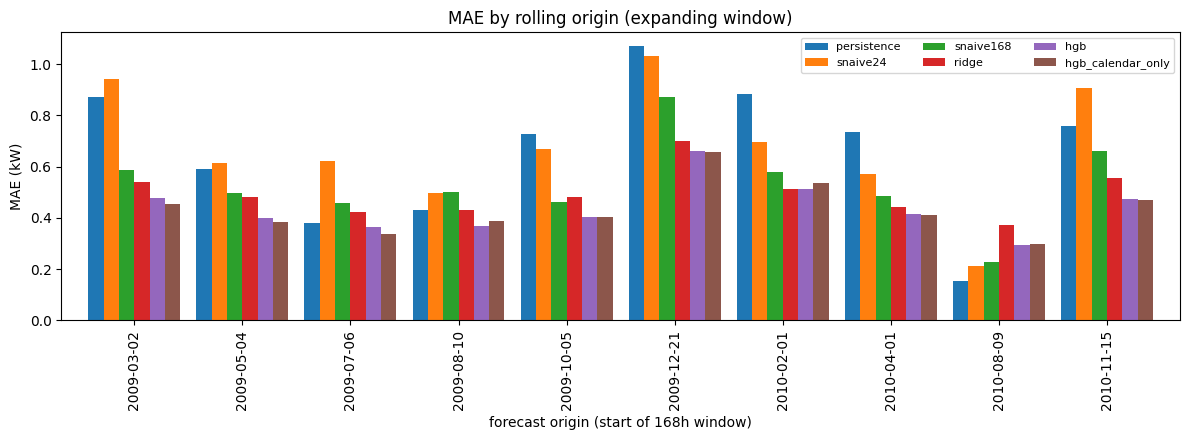

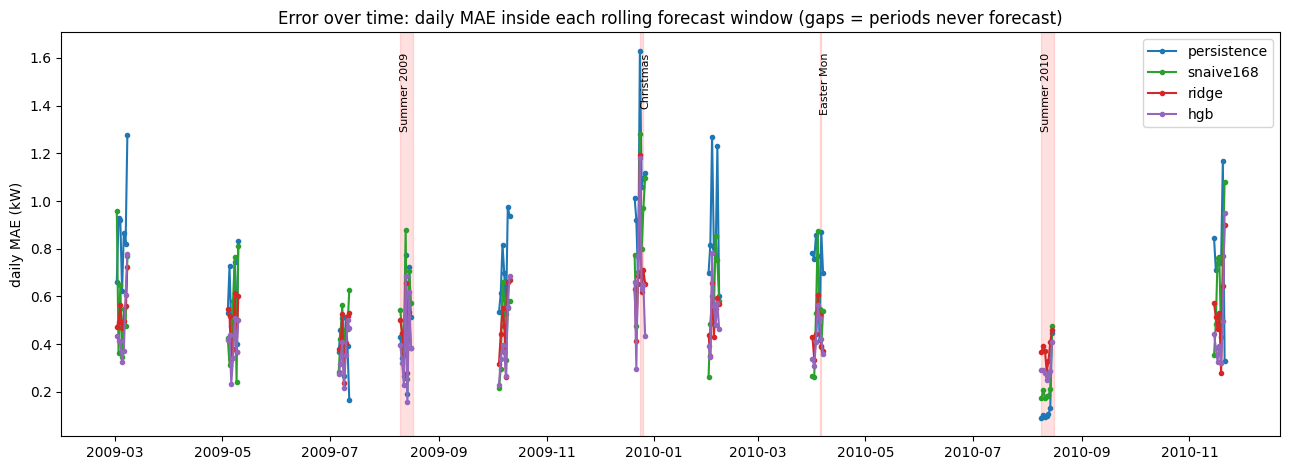

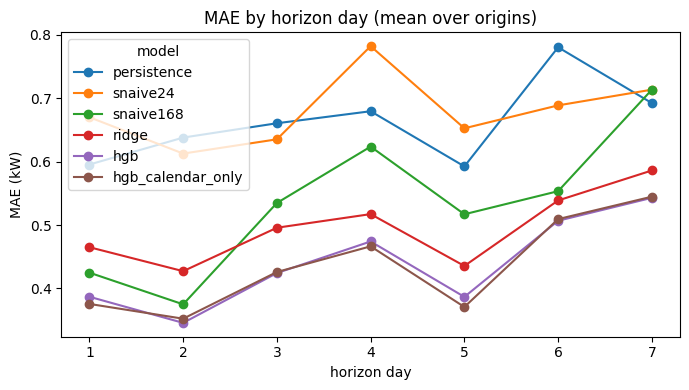

In [36]:
COL = dict(zip(MODELS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
origins = [pd.Timestamp(o) for o in ORIGIN_STARTS]

piv = met_origin.pivot(index="origin", columns="model", values="MAE")[MODELS]; piv.index = piv.index.strftime("%Y-%m-%d")
fig, ax = plt.subplots(figsize=(12, 4.5)); piv.plot.bar(ax=ax, width=0.85, color=[COL[m] for m in MODELS])
ax.set_ylabel("MAE (kW)"); ax.set_xlabel("forecast origin (start of 168h window)"); ax.set_title("MAE by rolling origin (expanding window)")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR/"fig1_mae_by_origin.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(13, 4.8))
for m in ["persistence","snaive168","ridge","hgb"]:
    for k, o in enumerate(origins):
        d = raw_exp[(raw_exp.model == m) & (raw_exp.origin == o)].groupby("day").abserr.mean()
        ax.plot(d.index, d.values, "o-", ms=3, color=COL[m], label=m if k == 0 else None)
for a, b, lab in [("2009-08-10","2009-08-17","Summer 2009"), ("2009-12-24","2009-12-26","Christmas"), ("2010-04-05","2010-04-06","Easter Mon"), ("2010-08-09","2010-08-16","Summer 2010")]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="red", alpha=0.12); ax.text(pd.Timestamp(a), ax.get_ylim()[1]*0.95, lab, fontsize=8, rotation=90, va="top")
ax.set_ylabel("daily MAE (kW)"); ax.set_title("Error over time: daily MAE inside each rolling forecast window (gaps = periods never forecast)"); ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"fig2_daily_error_over_time.png", dpi=150); plt.show()

raw_exp["hday"] = np.ceil(raw_exp.horizon_h / 24).astype(int)
hz = raw_exp.groupby(["model","hday"]).abserr.mean().unstack(0)[MODELS]
fig, ax = plt.subplots(figsize=(7,4)); hz.plot(ax=ax, marker="o", color=[COL[m] for m in MODELS]); ax.set_xlabel("horizon day"); ax.set_ylabel("MAE (kW)")
ax.set_title("MAE by horizon day (mean over origins)"); plt.tight_layout(); plt.savefig(FIG_DIR/"fig3_error_by_horizon.png", dpi=150); plt.show()
hz.to_csv(RES_DIR/"metrics_by_horizon_day.csv")

## Drift diagnosis

Three lenses, all computed only from data observable by the evaluation time:
* **Distribution shift** per origin: PSI and KS test of the test-window distribution vs (a) the last 28 observed days before `s` and (b) the same dates one year earlier (364 days; removes pure seasonality). Done for the target and, ex-post, for voltage, current and sub-meter 3.
* **Level / usage-pattern drift:** monthly mean demand by year and the 2010/2009 ratio.

      origin  psi_y_recent  psi_y_lastyear  ks_p_y_recent  ks_p_y_lastyear  mean_ratio_vs_recent  mean_ratio_vs_lastyear  psi_Voltage_recent  psi_Global_intensity_recent  psi_Sub_metering_3_recent  trailing28_yoy_ratio  bias_ridge  bias_hgb  bias_snaive168  mae_ratio_hgb_vs_snaive168
0 2009-03-02         0.460           0.504          0.026            0.086                 0.978                   0.963               0.111                        0.530                      0.042                 1.129      -0.079    -0.011           0.052                       0.812
1 2009-05-04         0.098           0.131          0.319            0.606                 0.952                   0.926               0.107                        0.081                      0.016                 1.065      -0.119    -0.010           0.022                       0.805
2 2009-07-06         0.170           0.154          0.003            0.026                 0.821                   0.843               0.411     

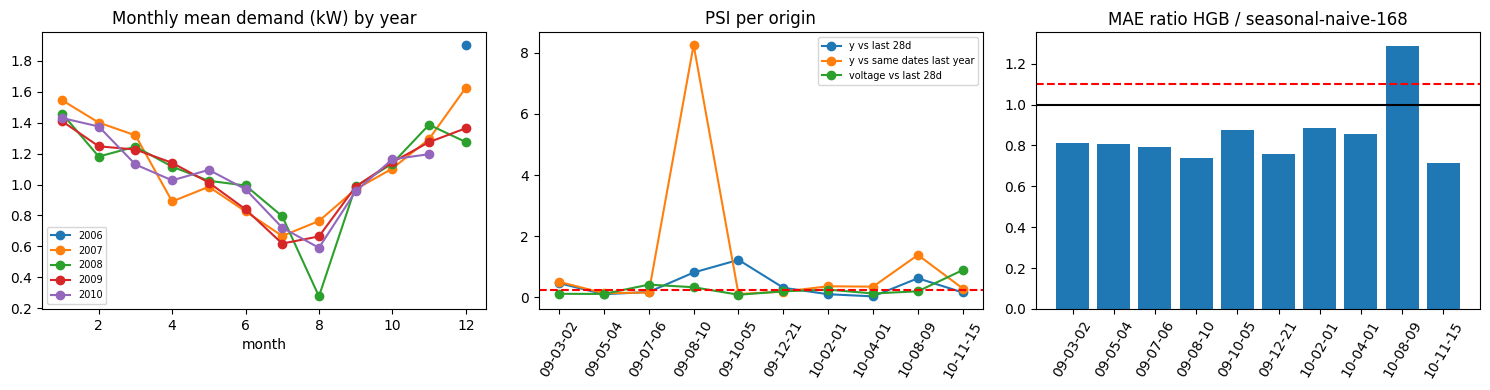

In [37]:
def rnd(d, n=3): return d.round({c: n for c in d.select_dtypes('number').columns})
def psi(ref, cur, bins=10):
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    ref, cur = ref[~np.isnan(ref)], cur[~np.isnan(cur)]
    if len(ref) < 20 or len(cur) < 20: return np.nan
    q = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(q) < 3: return np.nan
    q[0], q[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, q)[0] / len(ref), 1e-4, None); c = np.clip(np.histogram(cur, q)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))
def ks_p(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float); a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    return float(stats.ks_2samp(a, b).pvalue) if len(a) > 5 and len(b) > 5 else np.nan

H1 = pd.Timedelta(hours=1); rows = []
for s in origins:
    cur = df.loc[s: s + (HORIZON - 1) * H1]; rec = df.loc[s - pd.Timedelta(days=28): s - H1]
    ly_s = s - pd.Timedelta(days=364); ly = df.loc[ly_s: ly_s + (HORIZON - 1) * H1]
    r = dict(origin=s, psi_y_recent=psi(rec.y, cur.y), psi_y_lastyear=psi(ly.y, cur.y), ks_p_y_recent=ks_p(rec.y, cur.y), ks_p_y_lastyear=ks_p(ly.y, cur.y),
             mean_ratio_vs_recent=cur.y.mean() / max(rec.y.mean(), 1e-9), mean_ratio_vs_lastyear=cur.y.mean() / max(ly.y.mean(), 1e-9))
    for c in ("Voltage", "Global_intensity", "Sub_metering_3"): r[f"psi_{c}_recent"] = psi(rec[c], cur[c])
    t28 = df.loc[s - pd.Timedelta(days=28): s - H1].y.mean(); t28ly = df.loc[s - pd.Timedelta(days=392): s - pd.Timedelta(days=364) - H1].y.mean()
    r["trailing28_yoy_ratio"] = t28 / max(t28ly, 1e-9); rows.append(r)
drift = pd.DataFrame(rows)
bias = met_origin.pivot(index="origin", columns="model", values="Bias")[["ridge","hgb","snaive168"]].add_prefix("bias_")
mp_ = met_origin.pivot(index="origin", columns="model", values="MAE")
ratio = (mp_["hgb"] / mp_["snaive168"]).rename("mae_ratio_hgb_vs_snaive168")
drift = drift.set_index("origin").join(bias).join(ratio).reset_index(); drift.to_csv(RES_DIR/"drift_by_origin.csv", index=False)
print(rnd(drift).to_string())

mm = df.y.resample("MS").mean()
mtab = pd.DataFrame({"year": mm.index.year, "month": mm.index.month, "mean_kW": mm.values}).pivot(index="month", columns="year", values="mean_kW")
mtab["ratio_2010_over_2009"] = mtab[2010] / mtab[2009]; mtab.to_csv(RES_DIR/"monthly_level_by_year.csv"); print(rnd(mtab, 2).to_string())

sp = {}
for col in ("psi_y_recent", "psi_y_lastyear", "mean_ratio_vs_recent", "trailing28_yoy_ratio"):
    ok = drift[[col, "mae_ratio_hgb_vs_snaive168"]].dropna()
    if len(ok) >= 4: rho, p = stats.spearmanr(ok[col], ok["mae_ratio_hgb_vs_snaive168"]); sp[col] = dict(spearman_rho=float(rho), p=float(p), n=int(len(ok)))
print("Spearman(drift metric, HGB/snaive168 MAE ratio):", json.dumps(sp, indent=1)); (RES_DIR/"drift_vs_degradation_spearman.json").write_text(json.dumps(sp, indent=2))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for yr in sorted(set(mtab.columns) - {"ratio_2010_over_2009"}): axs[0].plot(mtab.index, mtab[yr], "o-", label=str(yr))
axs[0].set_title("Monthly mean demand (kW) by year"); axs[0].set_xlabel("month"); axs[0].legend(fontsize=7)
lab = drift.origin.dt.strftime("%y-%m-%d")
axs[1].plot(lab, drift.psi_y_recent, "o-", label="y vs last 28d"); axs[1].plot(lab, drift.psi_y_lastyear, "o-", label="y vs same dates last year")
axs[1].plot(lab, drift.psi_Voltage_recent, "o-", label="voltage vs last 28d"); axs[1].axhline(PSI_ALARM, color="r", ls="--"); axs[1].set_title("PSI per origin"); axs[1].tick_params(axis="x", rotation=60); axs[1].legend(fontsize=7)
axs[2].bar(lab, drift.mae_ratio_hgb_vs_snaive168); axs[2].axhline(1, color="k"); axs[2].axhline(FALLBACK_RATIO, color="r", ls="--"); axs[2].set_title("MAE ratio HGB / seasonal-naive-168"); axs[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG_DIR/"fig4_drift_diagnosis.png", dpi=150); plt.show()

## Critical-period failure analysis
Critical periods were named *before* modelling from calendar knowledge, not from results: the two French summer-holiday windows (household may be away; includes 15 Aug), the Christmas run-up, and the Easter window. Two views are computed for every model:
* **Origin-level:** window MAE divided by the mean MAE over the 6 *non-critical* origins.
* **Day-level:** MAE on the public-holiday days inside the window vs the rest of that window.

window MAE / mean MAE of non-critical origins:
model                                                 label    hgb  hgb_calendar_only  persistence  ridge  snaive168  snaive24
origin                                                                                                                        
2009-08-10    Summer holiday window (15 Aug holiday inside)  0.844              0.904        0.616  0.863      0.929     0.669
2009-12-21   Christmas / New Year run-up (24-25 Dec inside)  1.504              1.528        1.524  1.404      1.610     1.392
2010-04-01  Easter window (Easter Monday 2010-04-05 inside)  0.946              0.959        1.047  0.887      0.898     0.772
2010-08-09    Summer holiday window (15 Aug holiday inside)  0.675              0.692        0.218  0.746      0.424     0.285
                       period              model  MAE_inside  MAE_rest_of_window  ratio  bias_inside  actual_mean_inside  pred_mean_inside
0         Summer 2009: 15 Aug        persistence    

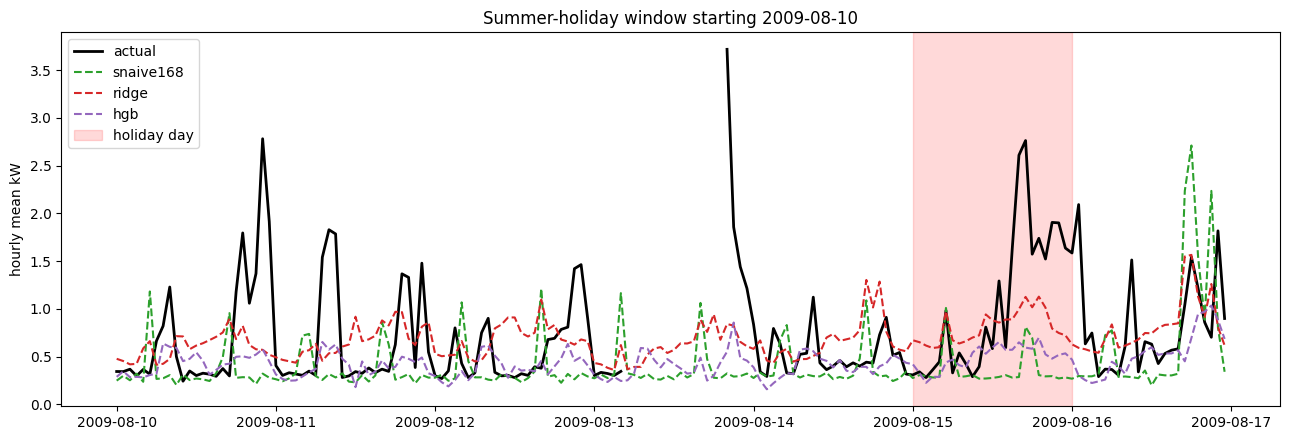

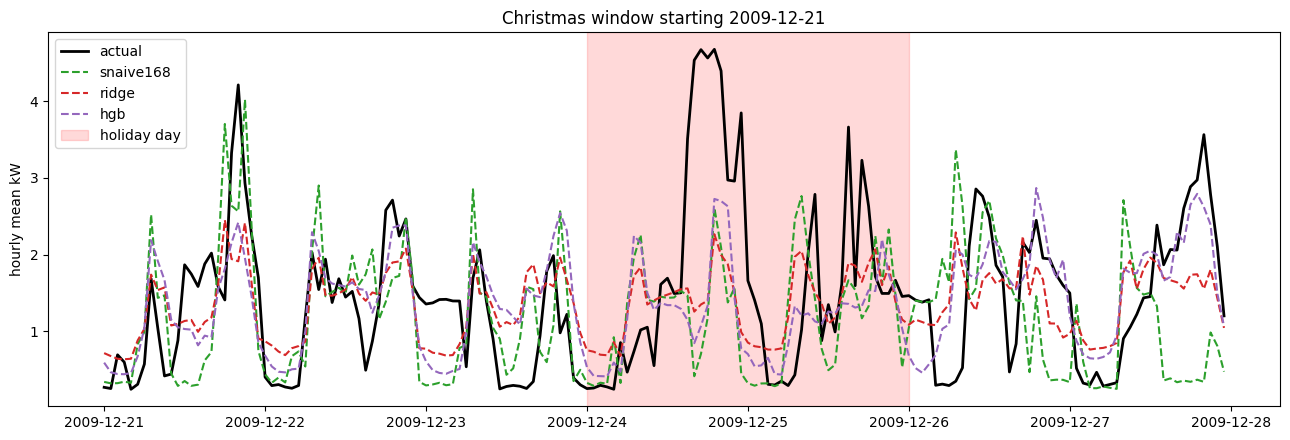

In [38]:
crit_keys = [pd.Timestamp(k) for k in CRITICAL_ORIGINS]
non_crit_mean = mp_[~mp_.index.isin(crit_keys)].mean()
crit_origin = (mp_.loc[crit_keys] / non_crit_mean).round(3); crit_origin.insert(0, "label", [CRITICAL_ORIGINS[k.strftime("%Y-%m-%d")] for k in crit_keys])
crit_origin.to_csv(RES_DIR/"critical_origin_mae_ratio.csv"); print("window MAE / mean MAE of non-critical origins:"); print(crit_origin.to_string())

HOLIDAY_DAYS = {"Summer 2009: 15 Aug": ("2009-08-15", "2009-08-15 23:00", "2009-08-10"), "Christmas 2009: 24-25 Dec": ("2009-12-24", "2009-12-25 23:00", "2009-12-21"),
                "Easter Monday 2010-04-05": ("2010-04-05", "2010-04-05 23:00", "2010-04-01"), "Summer 2010: 15 Aug": ("2010-08-15", "2010-08-15 23:00", "2010-08-09")}
rows = []
for name, (a, b, o) in HOLIDAY_DAYS.items():
    a, b, o = pd.Timestamp(a), pd.Timestamp(b), pd.Timestamp(o)
    for m in MODELS:
        r = raw_exp[(raw_exp.model == m) & (raw_exp.origin == o)]; ins = r[(r.ts >= a) & (r.ts <= b)]; out = r[(r.ts < a) | (r.ts > b)]
        rows.append(dict(period=name, model=m, MAE_inside=ins.abserr.mean(), MAE_rest_of_window=out.abserr.mean(), ratio=ins.abserr.mean() / max(out.abserr.mean(), 1e-9),
                         bias_inside=ins.err.mean(), actual_mean_inside=ins.y_true.mean(), pred_mean_inside=ins.y_pred.mean()))
crit = pd.DataFrame(rows); crit.to_csv(RES_DIR/"critical_period_errors.csv", index=False); print(rnd(crit, 3).to_string())

for fname, o, (a, b), ttl in [("fig5_critical_summer", "2009-08-10", ("2009-08-15","2009-08-16"), "Summer-holiday window starting 2009-08-10"),
                              ("fig6_critical_christmas", "2009-12-21", ("2009-12-24","2009-12-26"), "Christmas window starting 2009-12-21")]:
    sub = raw_exp[raw_exp.origin == pd.Timestamp(o)]; fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(sub[sub.model == "hgb"].ts, sub[sub.model == "hgb"].y_true, "k-", lw=2, label="actual")
    for m in ["snaive168", "ridge", "hgb"]: ax.plot(sub[sub.model == m].ts, sub[sub.model == m].y_pred, "--", color=COL[m], label=m)
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="red", alpha=0.15, label="holiday day"); ax.set_ylabel("hourly mean kW"); ax.legend(); ax.set_title(ttl)
    plt.tight_layout(); plt.savefig(FIG_DIR/f"{fname}.png", dpi=150); plt.show()

## Evidence that challenges the claim "the ML model is better"
Computed, not assumed: per-origin wins vs seasonal-naive-168, a paired Wilcoxon test over origins (n = 10, low power), the lag-free ablation, and expanding-vs-sliding differences. Kept even when unflattering.

In [39]:
mp = met_origin.pivot(index="origin", columns="model", values="MAE")[MODELS]
wins = {m: int((mp[m] < mp["snaive168"]).sum()) for m in ["ridge", "hgb", "hgb_calendar_only", "snaive24", "persistence"]}
losing = mp[mp["hgb"] >= mp["snaive168"]].index.strftime("%Y-%m-%d").tolist()
wil = {}
for m in ["ridge", "hgb"]:
    try: stt = stats.wilcoxon(mp[m], mp["snaive168"]); wil[m] = dict(stat=float(stt.statistic), p=float(stt.pvalue))
    except Exception as e: wil[m] = dict(error=repr(e))
exp_vs_sld = (mean_mae["MAE"] - mean_mae_sld["MAE"]).rename("MAE_expanding_minus_sliding")
chal = dict(origins_where_model_beats_snaive168=wins, origins_where_hgb_does_NOT_beat_snaive168=losing, wilcoxon_vs_snaive168=wil,
            ablation_mean_MAE=dict(hgb=float(mean_mae.loc["hgb","MAE"]), hgb_calendar_only=float(mean_mae.loc["hgb_calendar_only","MAE"])))
(RES_DIR/"challenge_evidence.json").write_text(json.dumps(chal, indent=2)); print(json.dumps(chal, indent=2)); print(exp_vs_sld.round(3).to_string())

{
  "origins_where_model_beats_snaive168": {
    "ridge": 8,
    "hgb": 9,
    "hgb_calendar_only": 9,
    "snaive24": 2,
    "persistence": 3
  },
  "origins_where_hgb_does_NOT_beat_snaive168": [
    "2010-08-09"
  ],
  "wilcoxon_vs_snaive168": {
    "ridge": {
      "stat": 11.0,
      "p": 0.10546875
    },
    "hgb": {
      "stat": 3.0,
      "p": 0.009765625
    }
  },
  "ablation_mean_MAE": {
    "hgb": 0.4373167892372842,
    "hgb_calendar_only": 0.4343687813410536
  }
}
model
persistence          0.000
snaive24             0.000
snaive168            0.000
ridge                0.003
hgb                 -0.017
hgb_calendar_only   -0.030


## Monitoring, retraining and fallback plan (implemented + retrospectively simulated)

**Signals** (computable at serving time once labels arrive, with a 1-hour lag):

| Signal | Computation | Threshold (a-priori, not tuned) | Action |
|---|---|---|---|
| Rolling error ratio | trailing MAE(model) / trailing MAE(`snaive168`), last full window | > 1.10 | **Fallback** to `snaive168` for the next window |
| Daily alarm | daily MAE(model) / daily MAE(`snaive168`) | > 1.5 | Alert; inspect events (holidays, occupant absence, meter outage) |
| Target drift | PSI of hourly demand (last 28 d vs previous 28 d / same dates last year) | > 0.25 | **Retrain trigger** + data review |
| Level drift | trailing-28-day year-over-year demand ratio | outside 0.8 - 1.25 | **Retrain trigger** (usage pattern changed) |
| Sensor / data quality | share of missing hours in last 24 h; reading outside [0, 1.5 x historical max kW]; stale feed | > 20 % missing, or out of range | **Fallback** to last good forecast / `snaive168`; block auto-retrain on corrupted data |
| Schedule | calendar | refit every ~5 weeks (similar to origin spacing here) | Routine refit with fresh imputer and scaler (as in this notebook) |

**Known-event rule:** windows containing public holidays or school/summer holidays are flagged *low confidence*. Because `snaive168` copies last week and can fail on such days too (compare the section 7 numbers before trusting it), the fallback there is a human-reviewed override rather than blind use of last week's value.

**Retrain gating:** a retrained model replaces production only if it beats the incumbent and `snaive168` on a time-ordered validation block that ends before the forecast start.

The cell below replays the first rules on the 10 origins using only earlier-window information. With n = 10 it is a **plausibility check, not proof**.

In [40]:
mae_p = met_origin.pivot(index="origin", columns="model", values="MAE")
prev_ratio = (mae_p[ML_PRIMARY] / mae_p["snaive168"]).shift(1)
use_fallback = (prev_ratio > FALLBACK_RATIO).fillna(False)
policy_mae = pd.Series(np.where(use_fallback, mae_p["snaive168"], mae_p[ML_PRIMARY]), index=mae_p.index)
pol = pd.DataFrame(dict(prev_window_ratio=prev_ratio, fallback_used=use_fallback, MAE_always_ml=mae_p[ML_PRIMARY], MAE_always_snaive168=mae_p["snaive168"], MAE_policy=policy_mae))
pol.to_csv(RES_DIR/"fallback_policy_simulation.csv"); print(pol.round(3).to_string())
policy_summary = dict(mean_MAE_policy=float(policy_mae.mean()), mean_MAE_always_ml=float(mae_p[ML_PRIMARY].mean()), mean_MAE_always_snaive168=float(mae_p["snaive168"].mean()), n_fallbacks=int(use_fallback.sum()))
print(policy_summary)

dm = raw_exp[raw_exp.model.isin([ML_PRIMARY, "snaive168"])].groupby(["origin", "day", "model"]).abserr.mean().unstack("model")
dm["ratio"] = dm[ML_PRIMARY] / dm["snaive168"].replace(0, np.nan)
alarms = dm[dm["ratio"] > ALARM_DAILY_RATIO].reset_index(); alarms.to_csv(RES_DIR/"daily_alarm_days.csv", index=False)
print(f"{len(alarms)} alarm days (ratio > {ALARM_DAILY_RATIO}) of {int(dm['ratio'].notna().sum())} evaluated days"); print(rnd(alarms, 2).to_string())
(RES_DIR/"policy_summary.json").write_text(json.dumps(dict(policy_summary, n_alarm_days=int(len(alarms)), n_days=int(dm['ratio'].notna().sum())), indent=2))

            prev_window_ratio  fallback_used  MAE_always_ml  MAE_always_snaive168  MAE_policy
origin                                                                                       
2009-03-02                NaN          False          0.477                 0.587       0.477
2009-05-04              0.812          False          0.401                 0.499       0.401
2009-07-06              0.805          False          0.363                 0.458       0.363
2009-08-10              0.793          False          0.370                 0.503       0.370
2009-10-05              0.737          False          0.404                 0.461       0.404
2009-12-21              0.877          False          0.660                 0.871       0.660
2010-02-01              0.757          False          0.513                 0.579       0.513
2010-04-01              0.886          False          0.415                 0.486       0.415
2010-08-09              0.854          False          0.296 

196